<a href="https://colab.research.google.com/github/krs524/XAI_Project/blob/main/notebooks/student_dropout.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluating Student Dropout Risk with Explainable AI: Simple but Faithful?

## Project Overview

This project examines whether simple explanations of student dropout-risk predictions can accurately reflect the behavior of an XGBoost model. Using the UCI student dropout dataset, I will compare TreeSHAP, LIME, and counterfactual explanations and evaluate their faithfulness, robustness, and usefulness for academic advising.

## Load the Dataset

This project uses the UCI Predict Students’ Dropout and Academic Success dataset. The dataset contains student demographic, socioeconomic, enrollment, and academic information together with three possible outcomes: Dropout, Enrolled, and Graduate.

In [31]:
!pip -q install ucimlrepo

In [32]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Load the UCI dataset
student_data = fetch_ucirepo(id=697)

# Separate input features and target
X = student_data.data.features.copy()
y = student_data.data.targets.copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (4424, 36)
Target shape: (4424, 1)



The dataset contains 4,424 student records, 36 input features, and one target variable.

In [33]:
df = X.copy()
df["Target"] = y.iloc[:, 0]

print("Complete dataset shape:", df.shape)

df.head()

Complete dataset shape: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## About Data

This section examines the basic structure and quality of the dataset, including the target classes, feature names, data types, missing values, and duplicate records. It provides an initial understanding of the data before preparing it for modeling.

In [34]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of input features:", X.shape[1])

Number of rows: 4424
Number of input features: 36


In [37]:
# Dataset structure and data types
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualificat

In [38]:
# Target distribution
target_summary = pd.DataFrame({
    "Count": df["Target"].value_counts(),
    "Percentage (%)": (
        df["Target"].value_counts(normalize=True) * 100
    ).round(2)
})

print("\nTarget distribution:")
display(target_summary)


Target distribution:


,Count,Percentage (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


In [39]:
# Missing values
missing_values = df.isna().sum()

print("\nTotal missing values:", missing_values.sum())
print("Columns with missing values:", (missing_values > 0).sum())

if (missing_values > 0).any():
    display(missing_values[missing_values > 0])


Total missing values: 0
Columns with missing values: 0


In [40]:
# Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [41]:
# Understand and Explore Categorical Features

categorical_examples = [
    "Marital Status",
    "Application mode",
    "Course",
    "Daytime/evening attendance"
]

for col in categorical_examples:
    print(f"{col}: {df[col].nunique()} unique values")

Marital Status: 6 unique values
Application mode: 18 unique values
Course: 17 unique values
Daytime/evening attendance: 2 unique values


## Data Preparation

The original dataset contains three outcomes: Dropout, Enrolled, and Graduate. For this project, students labeled `Enrolled` are excluded, and features unavailable by the end of the first semester will be reviewed before model training.

In [42]:
# Keep only Dropout and Graduate cases
binary_df = df[df["Target"].isin(["Dropout", "Graduate"])].copy()

# Encode the target: 1 = Dropout, 0 = Graduate
binary_df["Dropout"] = binary_df["Target"].map({
    "Graduate": 0,
    "Dropout": 1
})

print("Original dataset shape:", df.shape)
print("Binary dataset shape:", binary_df.shape)

# Binary class distribution
binary_summary = pd.DataFrame({
    "Count": binary_df["Target"].value_counts(),
    "Percentage (%)": (
        binary_df["Target"].value_counts(normalize=True) * 100
    ).round(2)
})

display(binary_summary)

Original dataset shape: (4424, 37)
Binary dataset shape: (3630, 38)


,Count,Percentage (%)
Target,,
Graduate,2209,60.85
Dropout,1421,39.15



## Feature Selection for Model Building

The model uses enrollment and background information along with first-semester academic performance to predict dropout risk. All six second-semester academic features were excluded to support earlier risk prediction. Financial and administrative features, including `Debtor`, `Tuition fees up to date`, and `Scholarship holder`, as well as economic indicators such as `Unemployment rate`, `Inflation rate`, and `GDP`, were retained for the preliminary model. However, their exact recording times could not be verified from the available dataset documentation.

In [43]:
# Identify all second-semester features
second_semester_cols = [
    col for col in binary_df.columns
    if "2nd sem" in col
]

print("Second-semester features to remove:")
for col in second_semester_cols:
    print("-", col)

Second-semester features to remove:
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (enrolled)
- Curricular units 2nd sem (evaluations)
- Curricular units 2nd sem (approved)
- Curricular units 2nd sem (grade)
- Curricular units 2nd sem (without evaluations)


In [44]:
# Create the feature matrix using information available by the end of Semester 1
X_model = binary_df.drop(
    columns=["Target", "Dropout"] + second_semester_cols
)

# Binary target: 1 = Dropout, 0 = Graduate
y_model = binary_df["Dropout"]

print("Number of students:", X_model.shape[0])
print("Number of model features:", X_model.shape[1])
print("Target shape:", y_model.shape)

Number of students: 3630
Number of model features: 30
Target shape: (3630,)


In [45]:
print("\nFeatures used by the model:")
for i, col in enumerate(X_model.columns, start=1):
    print(f"{i}. {col}")

print("\nAny second-semester features remaining?",
      any("2nd sem" in col for col in X_model.columns))


Features used by the model:
1. Marital Status
2. Application mode
3. Application order
4. Course
5. Daytime/evening attendance
6. Previous qualification
7. Previous qualification (grade)
8. Nacionality
9. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Curricular units 1st sem (credited)
23. Curricular units 1st sem (enrolled)
24. Curricular units 1st sem (evaluations)
25. Curricular units 1st sem (approved)
26. Curricular units 1st sem (grade)
27. Curricular units 1st sem (without evaluations)
28. Unemployment rate
29. Inflation rate
30. GDP

Any second-semester features remaining? False


## Feature Leakage Analysis

Before model training, the remaining features are reviewed to check whether they could be available by the end of the first semester and do not directly reveal the final student outcome.


In [46]:
# Group features based on when the information is available

enrollment_background = [
    "Marital Status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Previous qualification (grade)",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Admission grade",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "Age at enrollment",
    "International",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

first_semester = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)"
]

feature_review = pd.DataFrame({
    "Feature": enrollment_background + first_semester,
    "Feature Group": (
        ["Enrollment / Background"] * len(enrollment_background)
        + ["First Semester"] * len(first_semester)
    ),
    "Available by end of Semester 1": "Yes",
    "Initial Decision": "Keep"
})

display(feature_review)

,Feature,Feature Group,Available by end of Semester 1,Initial Decision
0,Marital Status,Enrollment / Background,Yes,Keep
1,Application mode,Enrollment / Background,Yes,Keep
2,Application order,Enrollment / Background,Yes,Keep
3,Course,Enrollment / Background,Yes,Keep
4,Daytime/evening attendance,Enrollment / Background,Yes,Keep
5,Previous qualification,Enrollment / Background,Yes,Keep
6,Previous qualification (grade),Enrollment / Background,Yes,Keep
7,Nacionality,Enrollment / Background,Yes,Keep
8,Mother's qualification,Enrollment / Background,Yes,Keep
9,Father's qualification,Enrollment / Background,Yes,Keep


In [47]:
assert set(feature_review["Feature"]) == set(X_model.columns)
assert feature_review["Feature"].is_unique

print("Features reviewed:", len(feature_review))
print("All model features accounted for:", True)

Features reviewed: 30
All model features accounted for: True


## Categorical and Numerical Features

Some features contain numerical codes that represent categories, while others contain measurements such as grades, age, and academic progress. We identify these groups to prepare the data correctly for XGBoost.


In [48]:
# Multi-category categorical variables to one-hot encode
categorical_features = [
    "Marital Status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# Binary variables already encoded as 0/1
binary_features = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Remaining variables are numerical or ordinal
numerical_features = [
    col for col in X_model.columns
    if col not in categorical_features + binary_features
]

# Verify that every feature is assigned to exactly one group
all_grouped_features = (
    categorical_features
    + binary_features
    + numerical_features
)

assert len(all_grouped_features) == len(set(all_grouped_features))
assert set(all_grouped_features) == set(X_model.columns)

print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))
print("Numerical / ordinal features:", len(numerical_features))
print("Total features:", len(X_model.columns))

print("\nCategorical features:")
for col in categorical_features:
    print("-", col)

print("\nBinary features:")
for col in binary_features:
    print("-", col)

print("\nNumerical / ordinal features:")
for col in numerical_features:
    print("-", col)

Categorical features: 9
Binary features: 8
Numerical / ordinal features: 13
Total features: 30

Categorical features:
- Marital Status
- Application mode
- Course
- Previous qualification
- Nacionality
- Mother's qualification
- Father's qualification
- Mother's occupation
- Father's occupation

Binary features:
- Daytime/evening attendance
- Displaced
- Educational special needs
- Debtor
- Tuition fees up to date
- Gender
- Scholarship holder
- International

Numerical / ordinal features:
- Application order
- Previous qualification (grade)
- Admission grade
- Age at enrollment
- Curricular units 1st sem (credited)
- Curricular units 1st sem (enrolled)
- Curricular units 1st sem (evaluations)
- Curricular units 1st sem (approved)
- Curricular units 1st sem (grade)
- Curricular units 1st sem (without evaluations)
- Unemployment rate
- Inflation rate
- GDP


## Train and Test Split

The dataset is divided into 80% training data and 20% testing data. A stratified split is used to keep the proportion of Dropout and Graduate students similar in both sets.

The training data will be used to fit the preprocessing steps and the XGBoost model, while the test data will be kept separate for evaluation. This allows the model to be evaluated on unseen data.

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set shape: (2904, 30)
Test set shape: (726, 30)

Training target distribution:
Dropout
0    60.85
1    39.15
Name: proportion, dtype: float64

Test target distribution:
Dropout
0    60.88
1    39.12
Name: proportion, dtype: float64


## Data Preprocessing

Categorical features are converted using one-hot encoding so that category codes are not treated as continuous numerical values. Numerical and ordinal features are kept unchanged, and the preprocessing steps are fitted only on the training data to avoid information leakage.

In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define preprocessing for categorical and numerical/ordinal features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Fit preprocessing only on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted preprocessing to the test data
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

Original training shape: (2904, 30)
Processed training shape: (2904, 213)

Original test shape: (726, 30)
Processed test shape: (726, 213)


In [51]:
# Get the names of the transformed features
processed_feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(processed_feature_names))

print("\nFirst 20 processed feature names:")
for name in processed_feature_names[:20]:
    print(name)

Number of processed features: 213

First 20 processed feature names:
categorical__Marital Status_1
categorical__Marital Status_2
categorical__Marital Status_3
categorical__Marital Status_4
categorical__Marital Status_5
categorical__Marital Status_6
categorical__Application mode_1
categorical__Application mode_2
categorical__Application mode_5
categorical__Application mode_7
categorical__Application mode_10
categorical__Application mode_15
categorical__Application mode_16
categorical__Application mode_17
categorical__Application mode_18
categorical__Application mode_26
categorical__Application mode_39
categorical__Application mode_42
categorical__Application mode_43
categorical__Application mode_44



## XGBoost Model Training

An XGBoost classifier is trained using the processed training data to predict student dropout or graduation. This initial model will provide a baseline for evaluating predictive performance before moving to the explainability analysis.

In [52]:
!pip -q install xgboost

In [53]:

from xgboost import XGBClassifier

# Define the initial XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Fit the model using training data only
xgb_model.fit(X_train_processed, y_train)

print("XGBoost model training complete.")

XGBoost model training complete.


In [54]:
# Predicted classes
y_pred = xgb_model.predict(X_test_processed)

# Predicted probability of Dropout (class 1)
y_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

## Model Evaluation

The trained XGBoost model is evaluated on the unseen test set using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. Since `Dropout` is encoded as class `1`, precision, recall, and F1-score primarily describe how well the model identifies students in the dropout class.

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Graduate", "Dropout"]
))

Accuracy:  0.872
Precision: 0.855
Recall:    0.810
F1-score:  0.832
ROC-AUC:   0.935

Confusion Matrix:
[[403  39]
 [ 54 230]]

Classification Report:
              precision    recall  f1-score   support

    Graduate       0.88      0.91      0.90       442
     Dropout       0.86      0.81      0.83       284

    accuracy                           0.87       726
   macro avg       0.87      0.86      0.86       726
weighted avg       0.87      0.87      0.87       726



The XGBoost model showed strong predictive performance on the held-out test set, achieving 87.2% accuracy and a ROC-AUC of 93.5%. For the Dropout class, the model achieved 85.5% precision, 81.0% recall, and an F1-score of 83.2%. These results suggest that the model can distinguish between students labeled Graduate and Dropout. However, they do not establish whether the explanations are faithful or useful to an academic advisor. Further validation would also be needed before considering the model for a real-world early-warning system.

## TreeSHAP Explanation

TreeSHAP is used to examine how individual features contribute to an XGBoost prediction. Initially, the goal is to confirm that a local explanation can be generated successfully for an individual student before conducting the full faithfulness and explanation-comparison analysis.

In [56]:
!pip -q install shap

In [57]:
import shap
import pandas as pd
import numpy as np

# Convert the processed test data into a DataFrame with feature names

if hasattr(X_test_processed, "toarray"):
    X_test_shap = pd.DataFrame(
        X_test_processed.toarray(),
        columns=processed_feature_names,
        index=X_test.index
    )
else:
    X_test_shap = pd.DataFrame(
        X_test_processed,
        columns=processed_feature_names,
        index=X_test.index
    )

print("SHAP test data shape:", X_test_shap.shape)

SHAP test data shape: (726, 213)


In [58]:
# Create TreeSHAP explanations for the test set
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_shap)

print("TreeSHAP explanations generated successfully.")
print("SHAP values shape:", shap_values.values.shape)

TreeSHAP explanations generated successfully.
SHAP values shape: (726, 213)


In [59]:
# Find the first correctly predicted Dropout student
correct_dropout_positions = np.where(
    (y_test.to_numpy() == 1) & (y_pred == 1)
)[0]

student_position = correct_dropout_positions[0]

print("Selected test-set position:", student_position)
print("Actual class: Dropout")
print("Predicted class:", "Dropout" if y_pred[student_position] == 1 else "Graduate")
print(f"Predicted dropout probability: {y_prob[student_position]:.3f}")

Selected test-set position: 7
Actual class: Dropout
Predicted class: Dropout
Predicted dropout probability: 0.974


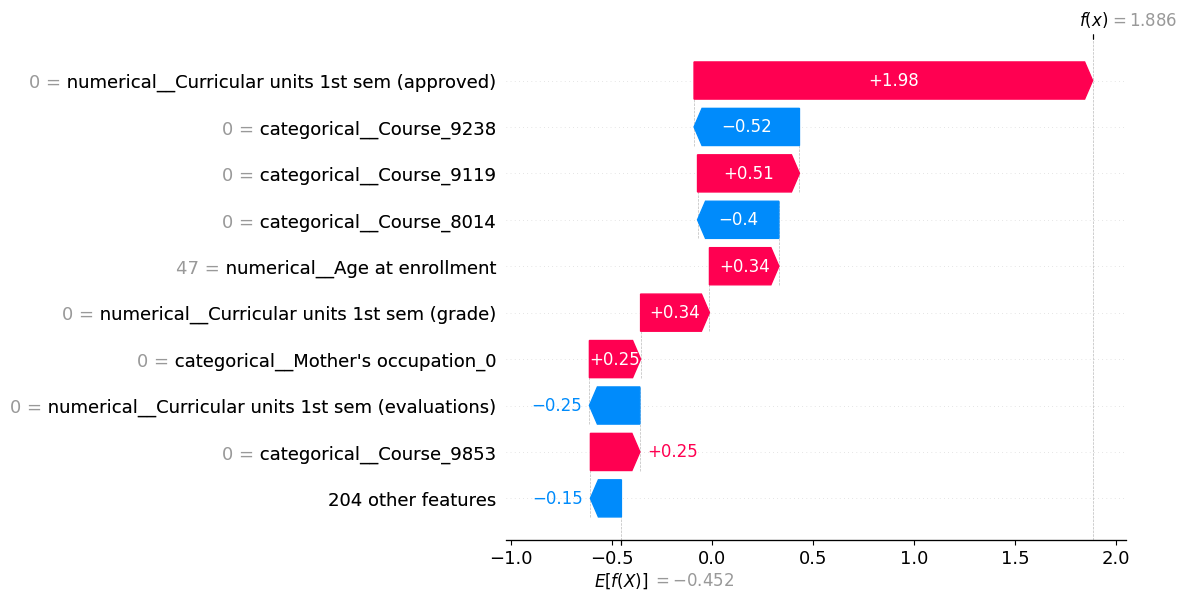

In [60]:
# Local TreeSHAP explanation for the selected student
shap.plots.waterfall(
    shap_values[student_position],
    max_display=10
)